# EfficientNet-B0 on the Corrected Binary Split

This notebook presents the separately trained model for `aptos2019_clean_binary_v1`. It does not train or tune the model. All checkpoints are selected by validation F1; the test decision rule remains argmax (equivalent to P(DR) > 0.5, with ties assigned to No DR).

If no evaluation has been saved, the cell below evaluates the frozen selected model. Otherwise it verifies and reuses the saved predictions without re-running test inference.

The test partition differs from the historical 366-image split. Changes in metrics are descriptive and cannot isolate the causal effect of deduplication.


In [1]:
from pathlib import Path
import os
import sys
project_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/dr_detection").is_dir() and (p / "configs").is_dir()), None
)
if project_root is None:
    raise RuntimeError("Open the notebook inside this project.")
sys.path.insert(0, str(project_root / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(project_root / ".mplconfig"))
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage
print(project_root)


/Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy


In [2]:
import torch
from dr_detection.clean_evaluation import evaluate_clean_model

torch.set_num_threads(4)
output_dir = project_root / "outputs/efficientnet_b0_clean_binary"
if not (output_dir / "training_summary.json").is_file():
    raise FileNotFoundError("Complete training with configs/efficientnet_b0_clean_binary.yaml first.")
result = evaluate_clean_model(project_root)
training = json.loads((output_dir / "training_summary.json").read_text())
print("Selected epoch:", result["best_epoch"])
print("Validation F1:", result["best_validation_f1"])
print("Test size:", result["test_size"])
print("Training device:", training["device"])


Verify image hashes:   0%|          | 0/3530 [00:00<?, ?it/s]

Verify image hashes: 100%|██████████| 3530/3530 [00:04<00:00, 740.19it/s]

Frozen clean test evaluation:   0%|          | 0/23 [00:00<?, ?it/s]

Frozen clean test evaluation:  39%|███▉      | 9/23 [00:05<00:08,  1.62it/s]

Frozen clean test evaluation:  83%|████████▎ | 19/23 [00:10<00:02,  1.81it/s]

Frozen clean test evaluation: 100%|██████████| 23/23 [00:12<00:00,  1.83it/s]

Selected epoch: 5
Validation F1: 0.9855072463768116
Test size: 354
Training device: mps


**Table 22.1. Corrected internal test predictions (first ten displayed)**


In [3]:
display(pd.read_csv(output_dir / "table_22_1_test_predictions.csv").head(10))


,source_split,id_code,diagnosis,image_path,status,error,file_sha256,pixel_sha256,phash,width,...,binary_label,label,original_grades,group_id,fold,split,true_label,predicted_label,dr_probability,outcome
0,valid,000c1434d8d7,2,data/raw/aptos2019/val_images/val_images/000c1...,ok,NaN,3f34b577a7102dddea20d2aaed76028bcf724ddb82e923...,485c6eba8de8dc587cf3dcfb1600030d640f1e80cf1f89...,7abd75b8527444c0,3216,...,1,1,2,similarity_000c1434d8d7,0,test,1,1,9.999924e-01,TP
1,valid,01b3aed3ed4c,1,data/raw/aptos2019/val_images/val_images/01b3a...,ok,NaN,cfe7d73ff89715046ddef7073d4e441045b89920e03e31...,e7a56f0b03e560e680d345abbf5296a1f9b864af0dae77...,5cfc53745c7441c1,2416,...,1,1,1,similarity_01b3aed3ed4c,0,test,1,1,9.985074e-01,TP
2,valid,01c7808d901d,2,data/raw/aptos2019/val_images/val_images/01c78...,ok,NaN,f50f542c63cad70bfde99633a4d554f08b90d54bd14d1a...,1f8f6ae0ac1c75b3206470fed72a2c9d39b9c2e31e51cf...,3cce71eb14bc41c1,4288,...,1,1,2,similarity_01c7808d901d,0,test,1,1,9.999999e-01,TP
3,valid,03a7f4a5786f,4,data/raw/aptos2019/val_images/val_images/03a7f...,ok,NaN,5a4edcca0e0b51572ce8e99b768874bef50877cae2b70c...,941bccb172f51f1f4a615de55579e1d8ce50520c92f82a...,6b6b34b4c9491794,2588,...,1,1,4,similarity_03a7f4a5786f,0,test,1,1,9.994332e-01,TP
4,valid,0423237770a7,0,data/raw/aptos2019/val_images/val_images/04232...,ok,NaN,bf1eb27b6344f4ff1c682133e42a10b68cbeaf5e130c10...,ec5eb5b0183c3cd1eab02b1edff0cc62c24f971fc013de...,5b6b24ae49f91494,1050,...,0,0,0,similarity_03a7f4a5786f,0,test,0,0,7.346955e-05,TN
5,valid,04efb1a284cc,0,data/raw/aptos2019/val_images/val_images/04efb...,ok,NaN,440b3ad644a4c0b250809522ab7a20f4755dd1ea63dc33...,35a59151b0d21984cab15f71fa7f6a8cb97d1202ac30a5...,4b6f26ae49f91484,1050,...,0,0,0,similarity_03a7f4a5786f,0,test,0,0,3.307721e-07,TN
6,valid,054b1b305160,0,data/raw/aptos2019/val_images/val_images/054b1...,ok,NaN,07c160fd695ba84d2827c49d95e8c8d6625049f867401e...,36da8261de2a29c2d8971e9b5670f57bc1029ea499be55...,292f5a6a2db944d4,1050,...,0,0,0,similarity_03a7f4a5786f,0,test,0,0,1.184324e-04,TN
7,valid,059bc89df7f4,1,data/raw/aptos2019/val_images/val_images/059bc...,ok,NaN,2e3db03e1bc6e6f0e23a8e8d74e92a4085716700f4d32e...,1bd1a7c71ecfc6b5b9053c9bab058fdccd5ad895240eab...,5cbc78f474f501c0,2416,...,1,1,1,similarity_059bc89df7f4,0,test,1,1,9.996082e-01,TP
8,valid,08a3875063c3,4,data/raw/aptos2019/val_images/val_images/08a38...,ok,NaN,e2fdfccbd0da5e73b60c99c101cd8673ea7e161bc4dcf4...,e1d8feaf07a9abdce9cd3479f4d538c060774a3d98a8fa...,44ba58bf05fd14d0,3216,...,1,1,4,similarity_08a3875063c3,0,test,1,1,9.999981e-01,TP
9,valid,094858f005ab,2,data/raw/aptos2019/val_images/val_images/09485...,ok,NaN,eee4d47c4b89402ae25b70656d497d214e6778d0ccedc8...,54949f1ca04c93b491d2993022cecd2be3c0de5ecf68d2...,47ad703d477550c4,2416,...,1,1,2,similarity_094858f005ab,0,test,1,1,9.999980e-01,TP


**Table 22.2. Corrected internal test metrics**


In [4]:
display(pd.read_csv(output_dir / "table_22_2_test_metrics.csv"))


,metric,value
0,accuracy,0.983051
1,precision,0.994118
2,recall,0.971264
3,f1,0.982558
4,roc_auc,0.995179
5,specificity,0.994444
6,loss,0.094818


**Table 22.3. Confusion counts**


In [5]:
display(pd.read_csv(output_dir / "table_22_3_confusion_counts.csv"))


,outcome,count
0,TN,179
1,FP,1
2,FN,5
3,TP,169


**Figure 22.1. Confusion matrix**


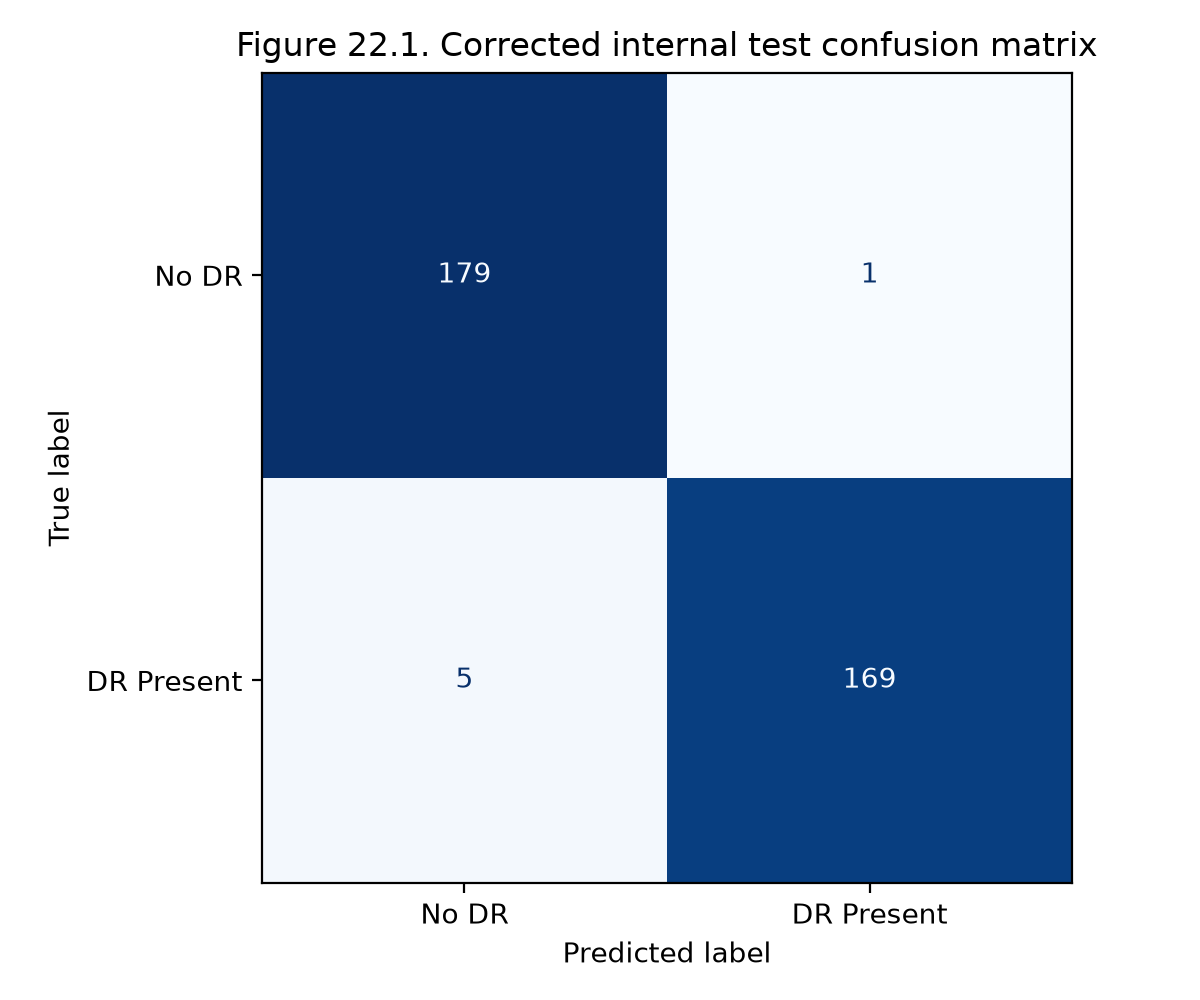

In [6]:
display(DisplayImage(filename=str(output_dir / "figure_22_1_confusion_matrix.png"), width=650))


**Figure 22.2. ROC curve**


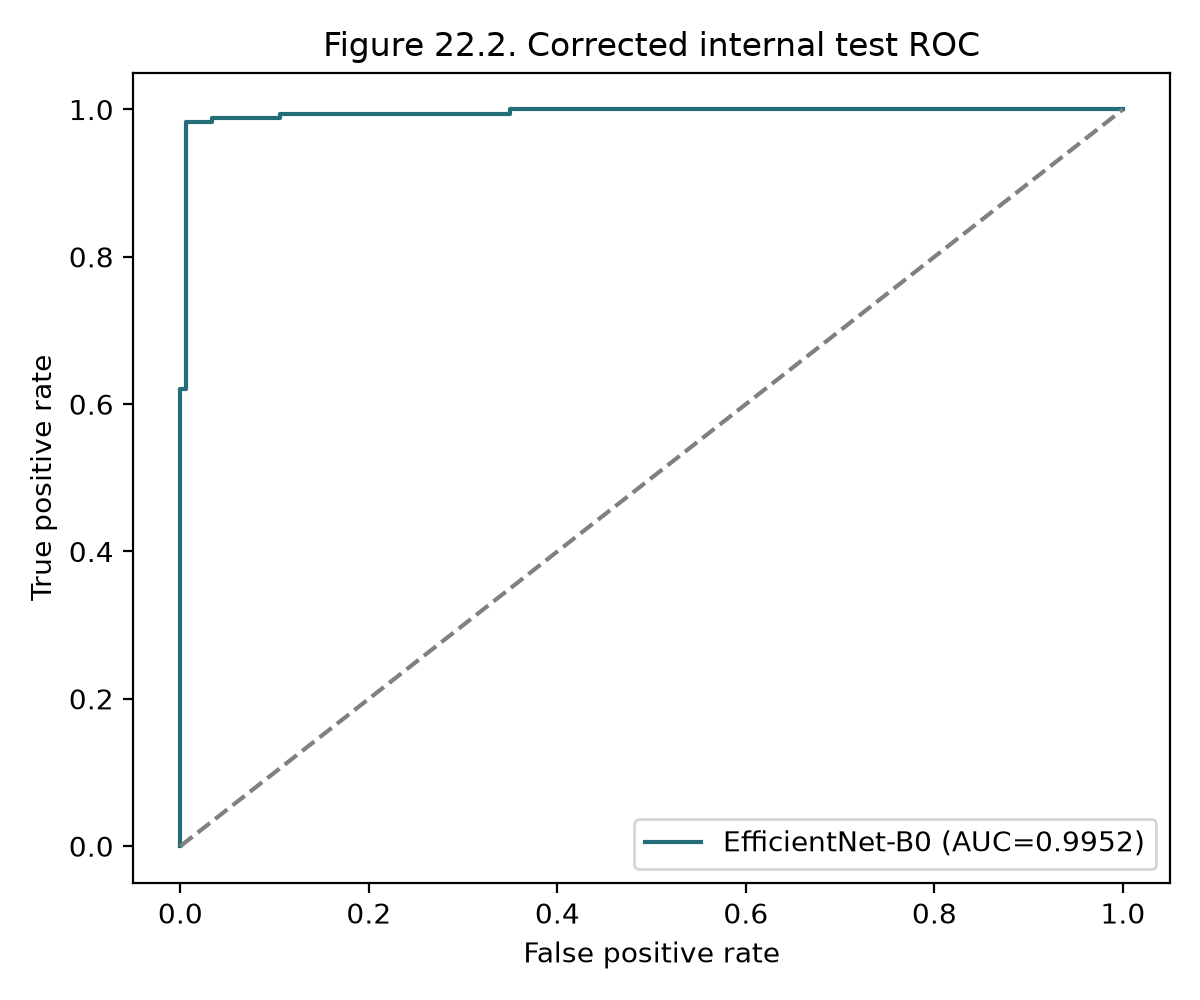

In [7]:
display(DisplayImage(filename=str(output_dir / "figure_22_2_roc_curve.png"), width=650))


**Table 22.5 and Figure 22.3. Training history and validation-only checkpoint selection**


,epoch,seconds,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,train_loss,valid_accuracy,valid_precision,valid_recall,valid_f1,valid_roc_auc,valid_loss
0,1,95.232084,0.940822,0.939438,0.940115,0.939776,0.983949,0.163919,0.977401,0.994048,0.959770,0.976608,0.998883,0.064794
1,2,97.229024,0.975904,0.974101,0.976912,0.975504,0.995215,0.080387,0.971751,0.993976,0.948276,0.970588,0.998436,0.069093
2,3,115.398596,0.975904,0.972063,0.979076,0.975557,0.996735,0.067691,0.977401,0.988235,0.965517,0.976744,0.999361,0.054696
3,4,125.450200,0.979802,0.980477,0.978355,0.979415,0.995735,0.075214,0.983051,0.994118,0.971264,0.982558,0.998755,0.053377
4,5,129.476950,0.987952,0.986331,0.989177,0.987752,0.999262,0.034861,0.985876,0.994152,0.977011,0.985507,0.999649,0.041473


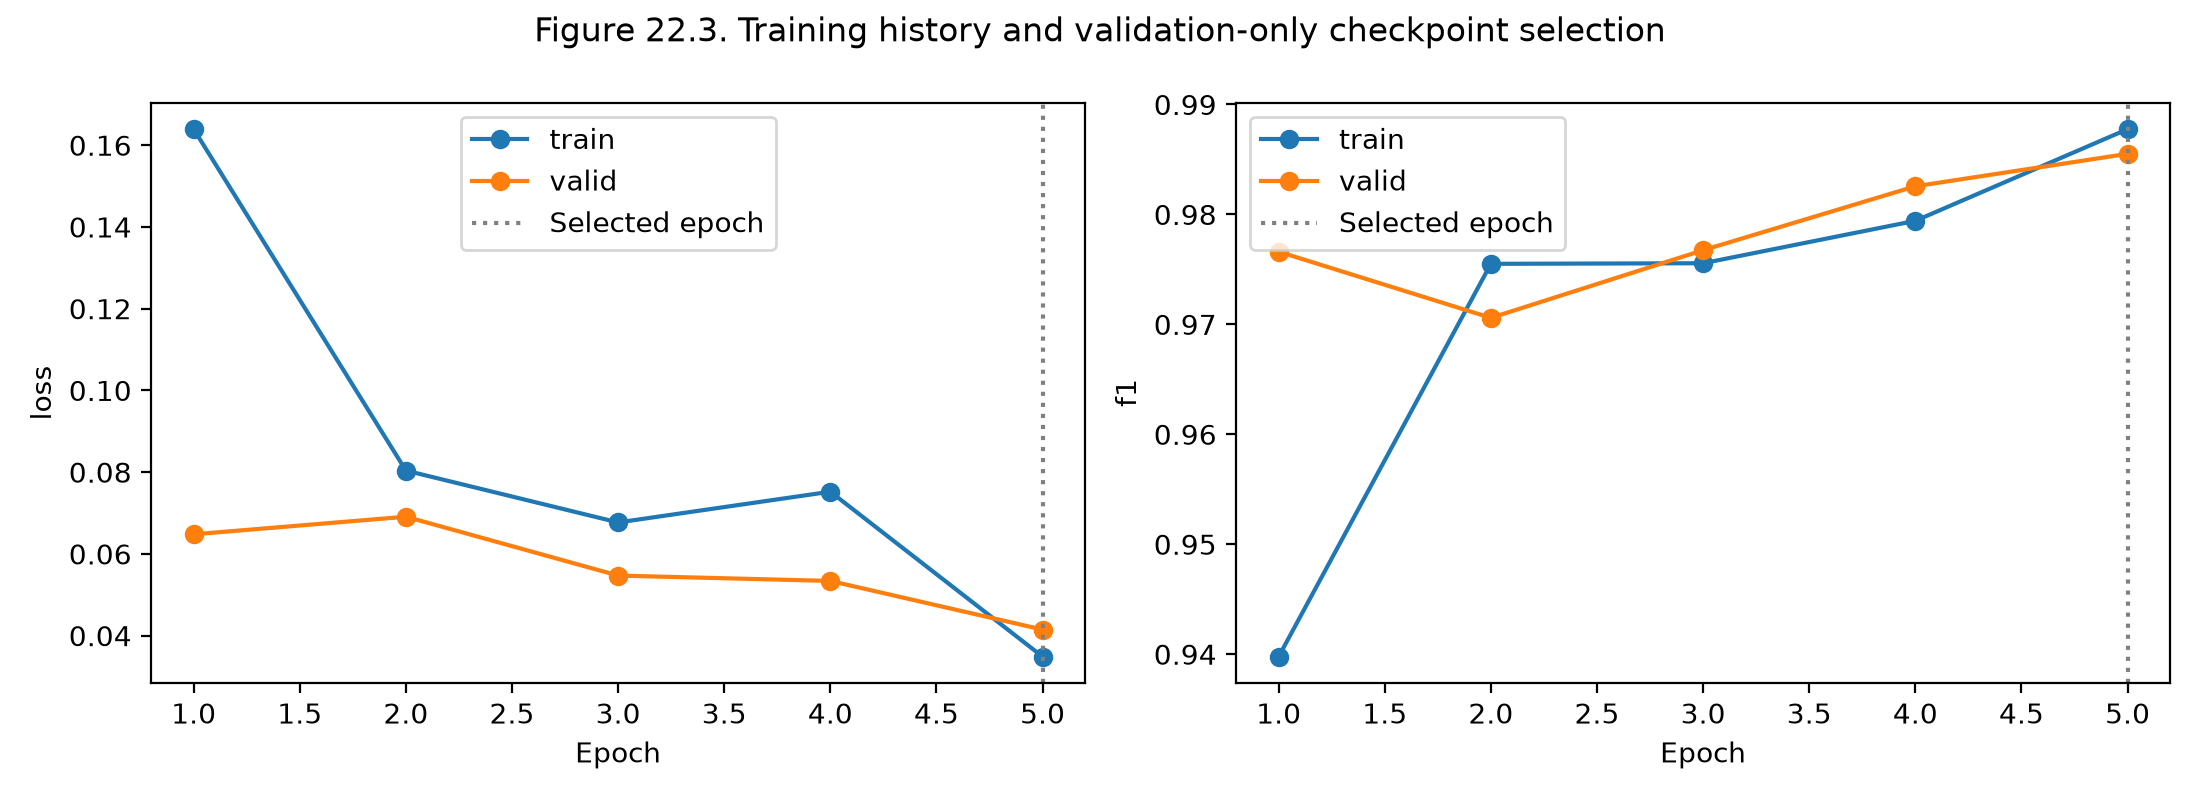

In [8]:
display(pd.read_csv(output_dir / "table_22_5_training_history.csv"))
display(DisplayImage(filename=str(output_dir / "figure_22_3_training_curves.png"), width=1000))


**Table 22.4. Every incorrectly classified test image**


In [9]:
errors = pd.read_csv(output_dir / "table_22_4_all_errors.csv")
display(errors[["id_code", "original_grades", "true_label", "predicted_label", "dr_probability", "outcome", "image_number"]])


,id_code,original_grades,true_label,predicted_label,dr_probability,outcome,image_number
0,513b0a4651fa,1,1,0,0.042471,FN,Image 22.1
1,73881f55a3ec,1,1,0,0.314205,FN,Image 22.2
2,a443c4fd489c,1,1,0,0.001047,FN,Image 22.3
3,d06ccd0cf4b8,1,1,0,0.383838,FN,Image 22.4
4,d5b4705ac2ee,1,1,0,0.000025,FN,Image 22.5
5,d9e58e4d8689,0,0,1,0.999650,FP,Image 22.6


## Grad-CAM for every error

Each numbered image shows the actual model input and maps for both class logits. Maps are independently normalized and are not lesion masks. Labels are dataset annotations, not a specialist review.


**Image 22.1. FN: 513b0a4651fa**

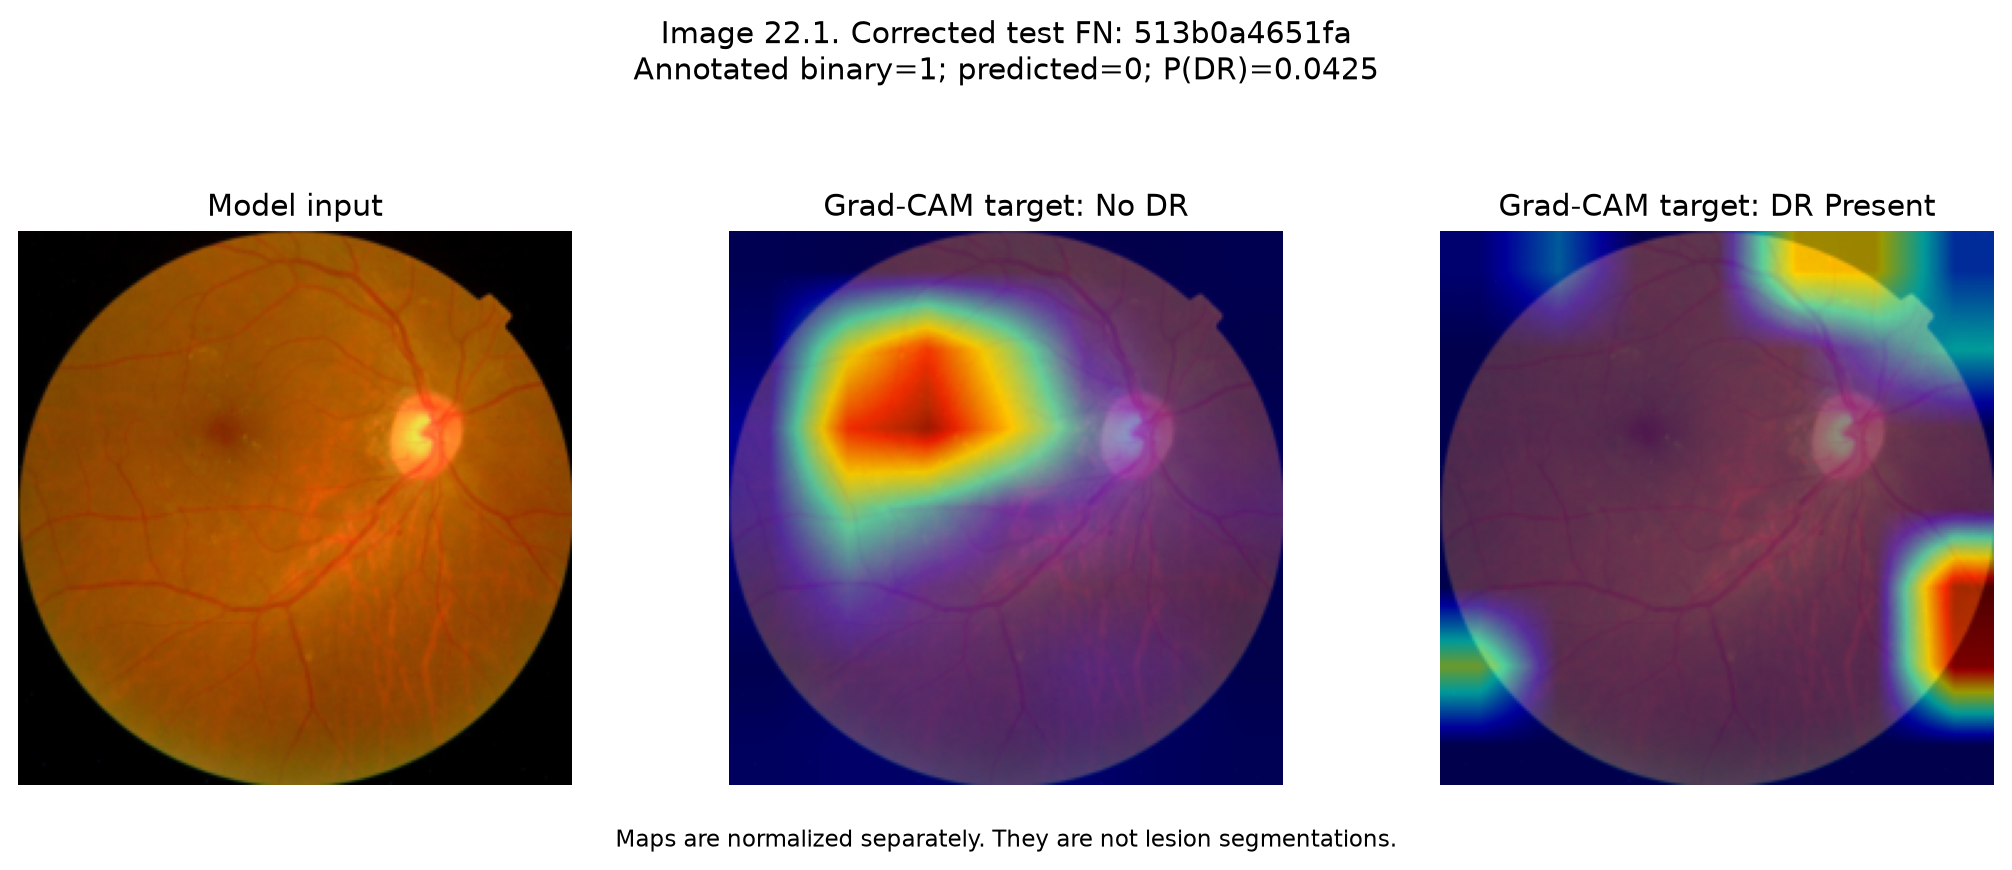

**Image 22.2. FN: 73881f55a3ec**

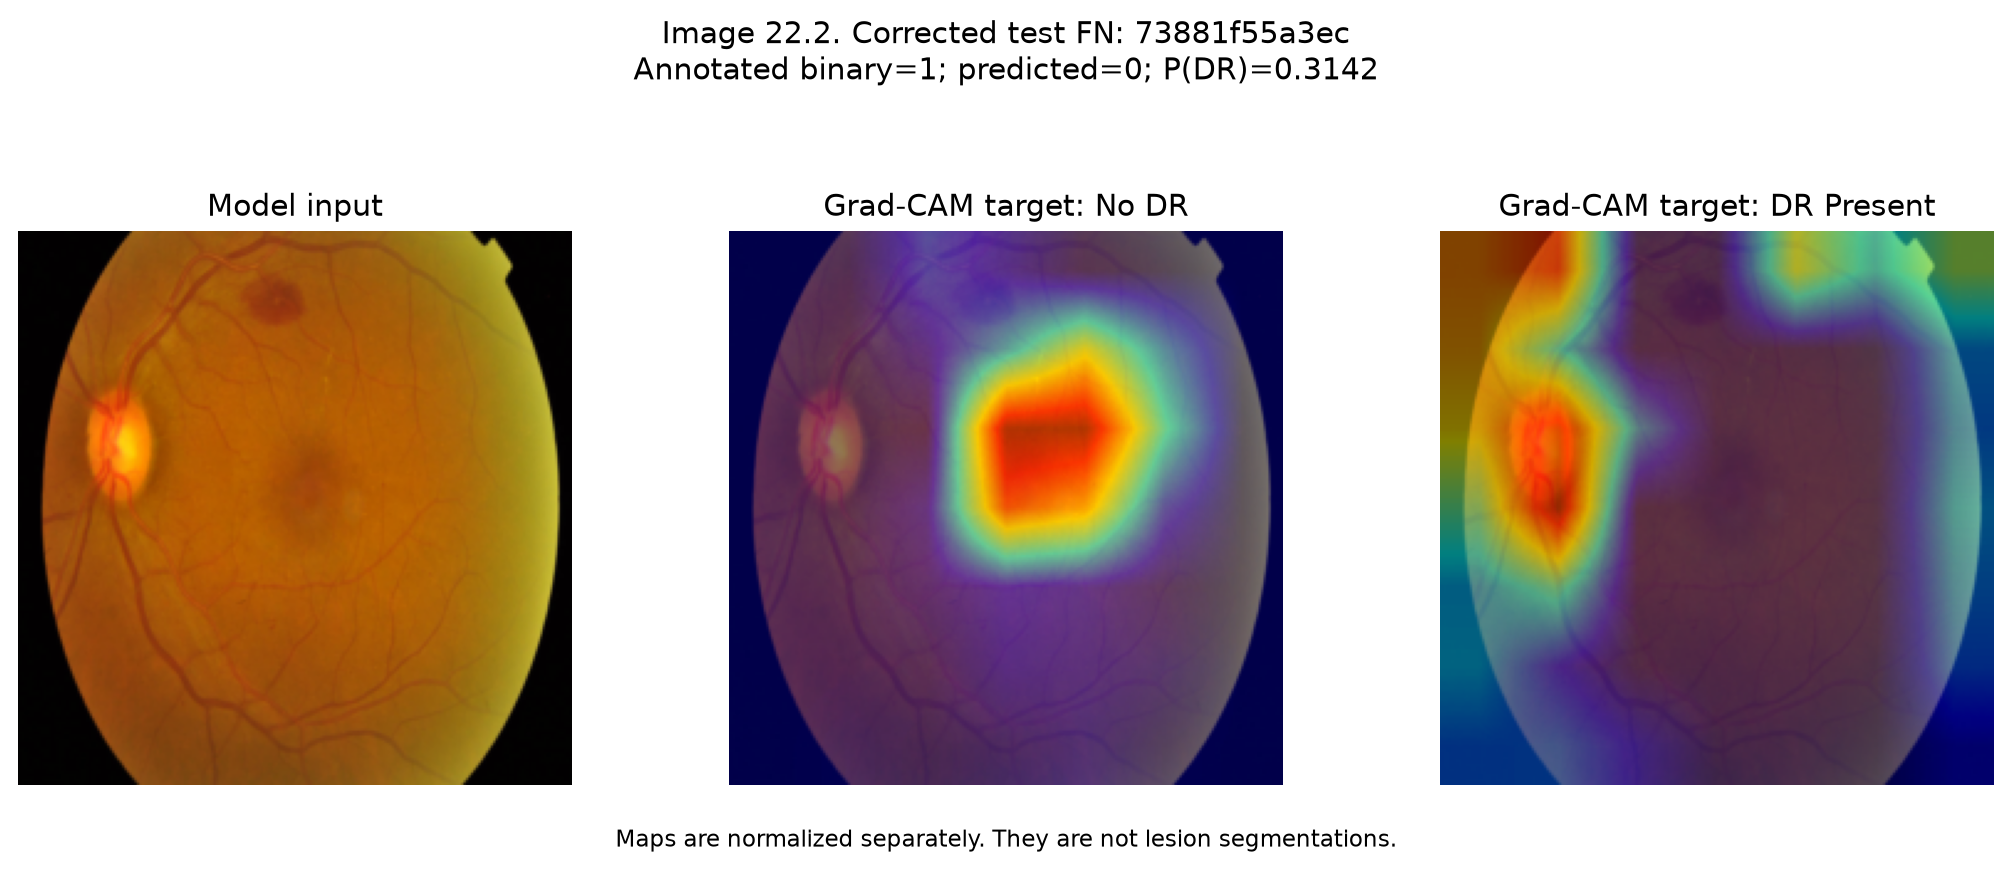

**Image 22.3. FN: a443c4fd489c**

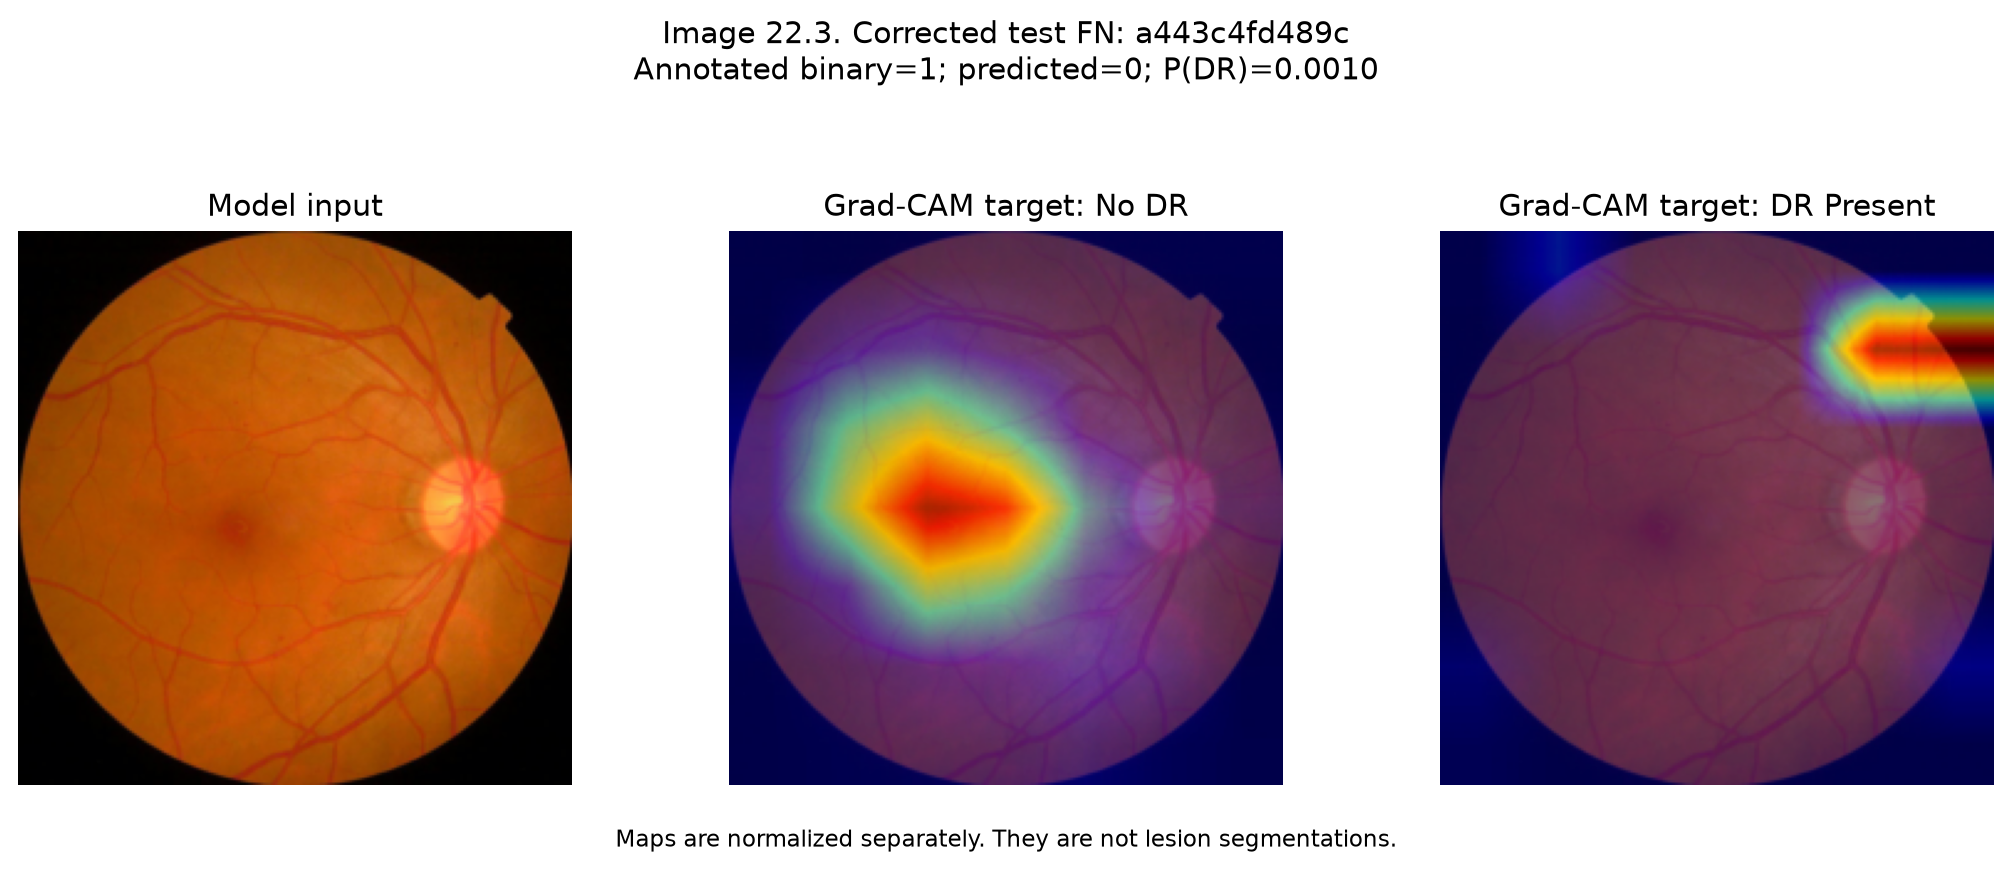

**Image 22.4. FN: d06ccd0cf4b8**

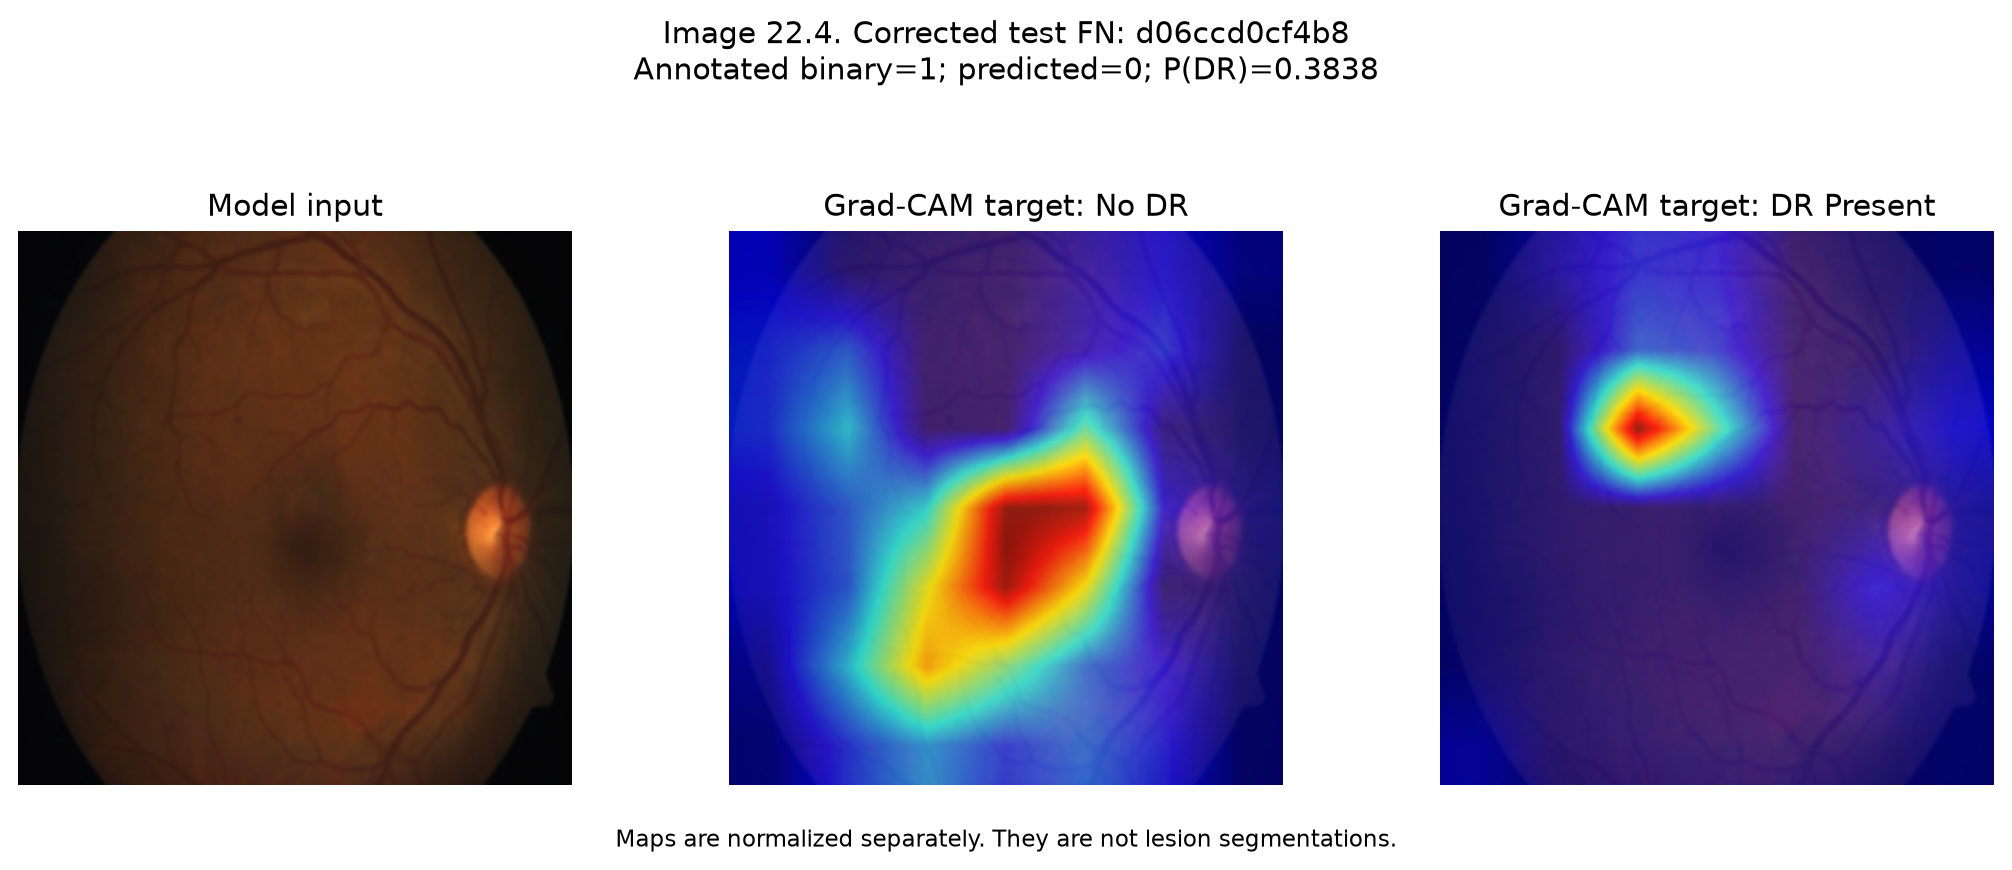

**Image 22.5. FN: d5b4705ac2ee**

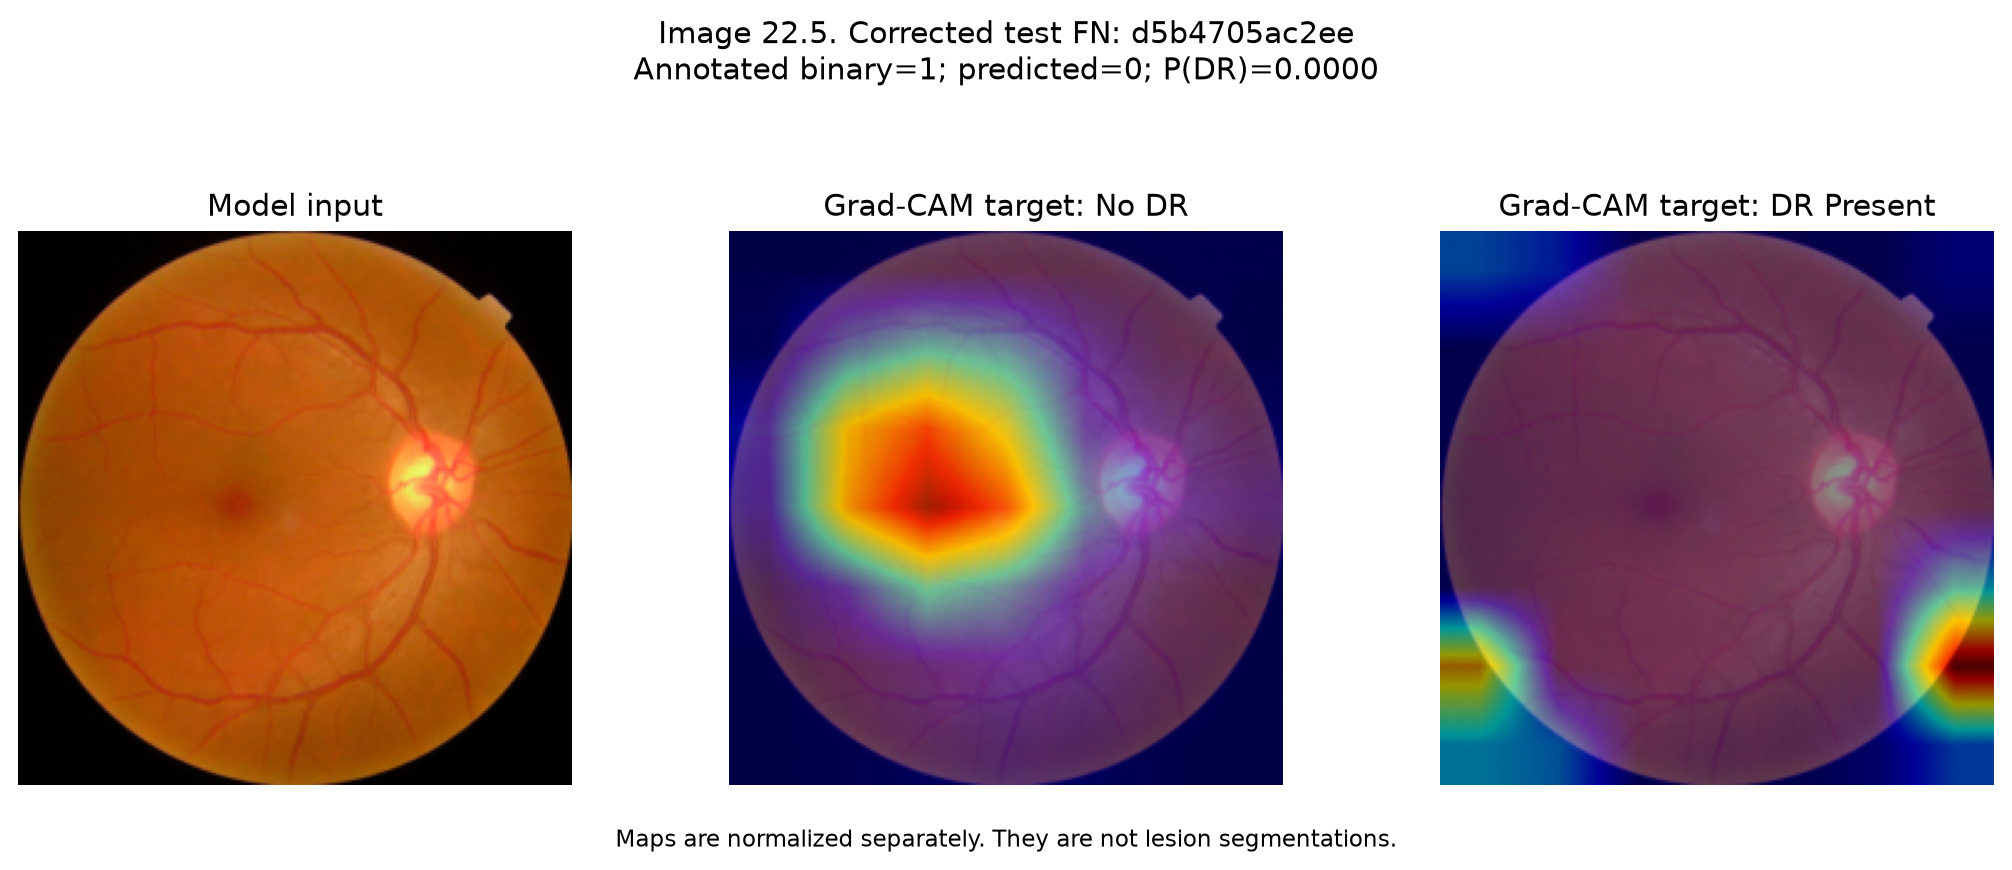

**Image 22.6. FP: d9e58e4d8689**

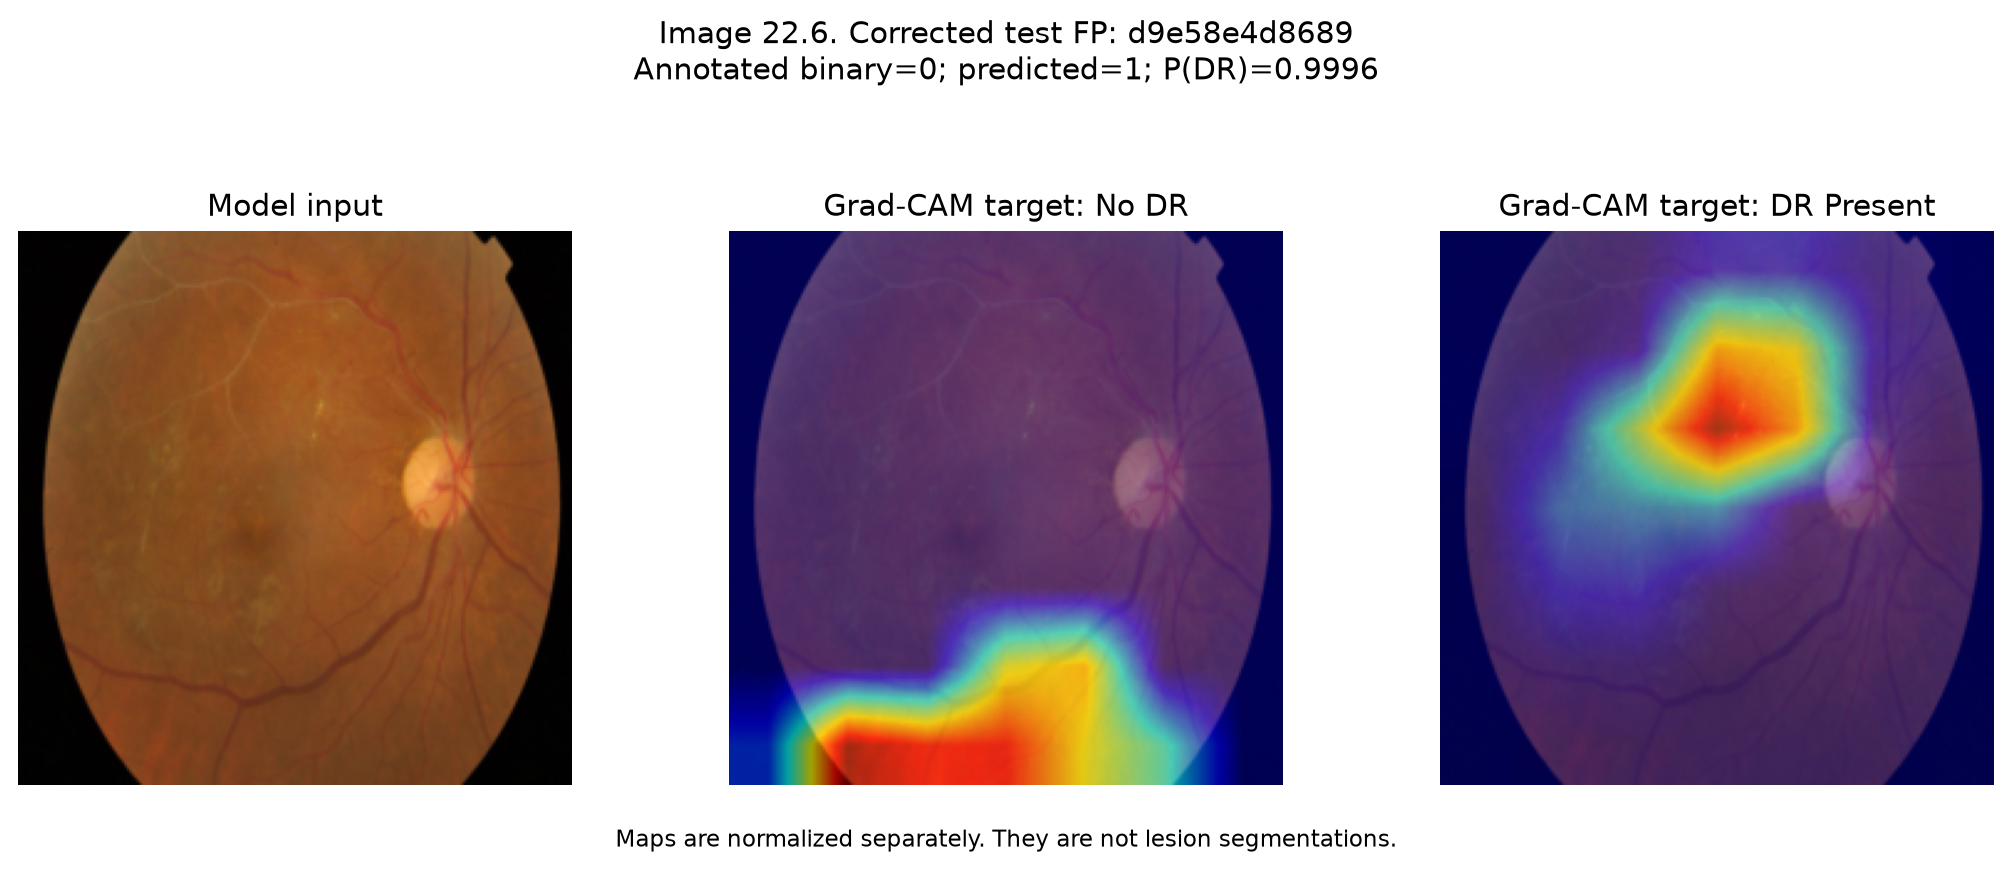

In [10]:
for row in errors.itertuples():
    display(Markdown(f"**{row.image_number}. {row.outcome}: {row.id_code}**"))
    display(DisplayImage(filename=str(output_dir / row.panel_file), width=1000))
if errors.empty:
    print("No incorrect predictions in this test partition.")


## Interpretation

The corrected experiment removes known exact overlap and prevents all detected pHash-neighbour connections from crossing the new split. It does not establish patient independence, clinical validity, or absence of every possible near-duplicate. The full dataset had already been used in exploratory experiments, and this remains internal validation.

Scores and visual explanations should be interpreted with those limits. The other architectures have not yet been retrained on this corrected split, so the historical ranking does not establish that B0 is the best architecture under the new protocol.

The full experimental record is in `notes/CLEAN_BINARY_EXPERIMENT.md`.
